# 07 — Vietnamese Symptom Extraction: Rule-based, Semantic và Hybrid

## 1. Câu hỏi nghiên cứu

Thí nghiệm so sánh nhận diện triệu chứng tiếng Việt bằng quy tắc, semantic candidate retrieval và hybrid. Đây là bài toán NLP riêng với phân loại bệnh; không huấn luyện LR hay mở final disease test.

**Cách chạy:** chọn kernel Colab rồi chạy các cell từ trên xuống. Hai switch bên dưới đã bật. Setup tự chuẩn bị source theo cấu trúc repository và dependencies NLP. Lần chạy Semantic đầu tiên tải embedding công khai từ publisher theo revision cố định; các lần sau dùng cache đã kiểm checksum trong `artifacts/embeddings/`. Cần kết nối Internet cho lần chuẩn bị đầu. Không cần API key, mount Drive, nhập đường dẫn hoặc upload từng file.

Nếu dùng Python local, mở notebook trong project và cài `requirements-nlp-research.txt` trong môi trường nghiên cứu riêng; notebook không tự cài đè môi trường API LR. Kết quả mỗi lần chạy nằm trong `reports/nlp_research_<timestamp>/`, bảng/hình phía dưới đọc chính thư mục này. Đặt RUN_RESEARCH=False chỉ khi muốn xem snapshot đối chiếu đã lưu.


In [1]:
RUN_RESEARCH = True
RUN_SEMANTIC = True
SAVE_REPORTS_TO_DRIVE = True


## Ba phương pháp khác nhau ở đâu?

| Phương pháp | Cách tìm triệu chứng | Context/evidence | Đầu ra trước khi xác nhận |
|---|---|---|---|
| Rule-based | Alias chính xác, normalization và word boundaries | Validator hiện có kiểm phủ định, subject, time, trích dẫn/hư cấu | Canonical states đã qua kiểm tra; ngoài từ điển thì hỏi/abstain |
| Semantic | Embedding từng clause, so độ tương đồng với375 descriptions | Kiểm context trên span gốc trước khi giữ ứng viên | Top3 feature candidates + cosine + assertion; chưa tự thêm vào vector |
| Hybrid | Giữ validated rule states; retrieval bổ sung khi chưa bị rule state bao phủ | Không override denied/uncertain/subject; candidate cần xác nhận | Rule states + danh sách ứng viên bổ sung |

Đây là **hai tầng đánh giá**: (1) triệu chứng đã xác minh, (2) chất lượng truy hồi ứng viên. Không giả lập câu trả lời người dùng để làm Semantic có F1 cao hơn. Hybrid có thể bằng Rule-based ở tầng1 nếu chưa xác nhận thêm candidates; kết quả đó vẫn có ý nghĩa và phải được báo đúng.


In [2]:
from pathlib import Path
import os, sys, subprocess, importlib.util, importlib.metadata

# Use the same repository structure on Windows and Colab. No individual uploads.
IS_COLAB = sys.platform.startswith('linux') and Path('/content').is_dir()
REPOSITORY = 'https://github.com/Leafguy2341/disease-prediction-ml.git'
SOURCE_BRANCH = 'feat/vietnamese-nlp-research'
REQUIRED_SOURCE = ('configs/nlp_research.json', 'scripts/nlp_symptom_research.py',
                   'scripts/plot_nlp_research.py', 'requirements-nlp-research.txt',
                   'reports/nlp_research_v1/figure_manifest.json',
                   'data/evaluation/vietnamese_nlp_reserved_v1.jsonl',
                   'artifacts/metadata/phase2/feature_schema.json',
                   'artifacts/metadata/phase2/label_mapping.json')
candidates = [Path.cwd(), *Path.cwd().parents]
if os.environ.get('NLP_PROJECT_ROOT'):
    candidates.insert(0, Path(os.environ['NLP_PROJECT_ROOT']).expanduser())
candidates.extend((Path.cwd()/'disease-prediction-ml-git-sync', Path.cwd()/'disease-prediction-ml'))
SOURCE_UPDATED = False
SOURCE = next((p.resolve() for p in candidates if all((p/n).is_file() for n in REQUIRED_SOURCE)), None)
if SOURCE is None:
    if not IS_COLAB:
        raise RuntimeError('Mở notebook từ project trong VS Code và chọn kernel Python nghiên cứu. Source cần có configs/, scripts/ và data/evaluation/.')
    SOURCE = Path('/content/disease-prediction-ml-nlp')
    if not SOURCE.exists():
        print('Đang chuẩn bị source GitHub trong Colab...', flush=True)
        subprocess.run(['git','clone','--branch',SOURCE_BRANCH,'--single-branch',REPOSITORY,str(SOURCE)], check=True, capture_output=True, text=True)
    elif (SOURCE/'.git').is_dir():
        remote = subprocess.check_output(['git','-C',str(SOURCE),'remote','get-url','origin'],text=True).strip()
        if remote.removesuffix('.git') != REPOSITORY.removesuffix('.git'):
            raise RuntimeError('Folder source Colab thuộc repository khác; không ghi đè.')
        dirty = subprocess.check_output(['git','-C',str(SOURCE),'status','--porcelain'],text=True).strip()
        if dirty:
            raise RuntimeError('Source Colab có thay đổi local; giữ nguyên để tránh ghi đè. Dùng runtime mới.')
        subprocess.run(['git','-C',str(SOURCE),'fetch','origin',SOURCE_BRANCH],check=True,capture_output=True,text=True)
        subprocess.run(['git','-C',str(SOURCE),'merge','--ff-only','FETCH_HEAD'],check=True,capture_output=True,text=True)
    missing = [n for n in REQUIRED_SOURCE if not (SOURCE/n).is_file()]
    if missing:
        raise RuntimeError('Source chưa đầy đủ: '+', '.join(missing))
    SOURCE_UPDATED = True
if SOURCE is not None and IS_COLAB and not SOURCE_UPDATED and (SOURCE/'.git').is_dir():
    remote = subprocess.check_output(['git','-C',str(SOURCE),'remote','get-url','origin'],text=True).strip()
    if remote.removesuffix('.git') != REPOSITORY.removesuffix('.git'):
        raise RuntimeError('Source repository khác cấu hình; không cập nhật tự động.')
    if subprocess.check_output(['git','-C',str(SOURCE),'status','--porcelain'],text=True).strip():
        raise RuntimeError('Source Colab có chỉnh sửa local; giữ nguyên, dùng runtime mới để cập nhật.')
    subprocess.run(['git','-C',str(SOURCE),'fetch','origin',SOURCE_BRANCH],check=True,capture_output=True,text=True)
    subprocess.run(['git','-C',str(SOURCE),'merge','--ff-only','FETCH_HEAD'],check=True,capture_output=True,text=True)
if SOURCE is not None:
    os.environ['NLP_PROJECT_ROOT'] = str(SOURCE)
    print('Source:', SOURCE)
    if (SOURCE/'.git').is_dir():
        print('Commit:', subprocess.check_output(['git','-C',str(SOURCE),'rev-parse','HEAD'],text=True).strip())
if RUN_RESEARCH and RUN_SEMANTIC:
    expected = {'sentence-transformers':'5.1.2', 'transformers':'4.57.1', 'huggingface-hub':'0.36.0'}
    def package_version(name):
        try: return importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError: return None
    if any(package_version(name)!=version for name,version in expected.items()):
        if not IS_COLAB:
            raise RuntimeError('Cài requirements-nlp-research.txt bằng interpreter nghiên cứu riêng; không dùng môi trường API LR. Colab tự chuẩn bị dependencies ở cell này.')
        print('Đang chuẩn bị thư viện NLP cho runtime Colab...', flush=True)
        install = subprocess.run([sys.executable,'-m','pip','install','--quiet','-r',str(SOURCE/'requirements-nlp-research.txt')],capture_output=True,text=True)
        if install.returncode:
            raise RuntimeError('Cài dependencies NLP thất bại. '+install.stderr[-1600:])
    print('Thư viện NLP:', {name:package_version(name) for name in expected})

import json, hashlib
from IPython.display import display, Markdown, Image

ROOT = SOURCE
REPORT = ROOT / 'reports/nlp_research_v1'
reference_manifest = json.loads((REPORT / 'figure_manifest.json').read_text(encoding='utf-8'))

def snapshot_bytes(name):
    if name not in reference_manifest['files']:
        raise ValueError('Unknown saved report file: ' + name)
    raw = (REPORT / name).read_bytes()
    if hashlib.sha256(raw).hexdigest() != reference_manifest['files'][name]:
        raise ValueError('Saved report checksum mismatch: ' + name)
    return raw

def snapshot_json(name):
    return json.loads(snapshot_bytes(name).decode('utf-8'))

protocol = json.loads((ROOT / 'configs/nlp_research.json').read_text(encoding='utf-8'))
saved = snapshot_json('benchmark.json')
inventory = snapshot_json('coverage_inventory.json')
after = snapshot_json('context_after_fix.json')
print('Source và dữ liệu đối chiếu đã sẵn sàng. Kết quả lần chạy mới hiện ở mục 6.')


Source: D:\Program Files (x86)\DULIEUCODE\ML\disease-prediction-ml-git-sync
Commit: 37abb9f8ed28ca27d03deaef3933d811001c2e5f
Thư viện NLP: {'sentence-transformers': '5.1.2', 'transformers': '4.57.1', 'huggingface-hub': '0.36.0'}
Source và dữ liệu đối chiếu đã sẵn sàng. Kết quả lần chạy mới hiện ở mục 6.


## 2. Benchmark và provenance

86 fixtures tiếng Việt lịch sử chỉ dùng development; 63 câu có expected states đầy đủ, 23 câu chỉ gán nhãn từng phần/forbidden features. Không coi phần chưa gán nhãn là negative. Thêm 32 câu reserved synthetic v1, pending_human_review, không dùng trong alias probes/threshold selection; exact normalized text không giao nhau giữa hai tập. Cùng tác giả và khái niệm triệu chứng vẫn tạo bias: đây không phải bộ bệnh nhân độc lập hoặc clinical validation.

Mỗi ca mới ghi canonical states, subject=self, ambiguity, evidence offsets khi có, provenance và flags tách evaluation khỏi development. Các ca other-subject/hư cấu kỳ vọng không có state cho người dùng. Fixture lịch sử không có span gold được ghi nhận giới hạn, không bịa span annotation.

**Reserved đã được quan sát trong lần baseline đầu**, phát hiện hai false positive hư cấu. Giữ nguyên kết quả trước sửa; không chạy lại để gọi đó là cải thiện độc lập. Cần bộ NLP evaluation mới được người duyệt trước kết luận tổng quát hoặc chọn threshold. Đây không phải locked final disease test.


In [3]:
display(protocol)
for split, methods in saved['results'].items():
    m = methods['rule_based']['metrics']
    print(split, '| cases:', m['cases'], '| fully annotated:', m['fully_annotated_cases'], '| partial:', m['partial_label_cases'])
display(saved['inputs_sha256'])
display(saved['baseline_source_sha256'])


{'protocol': 'vietnamese-nlp-research-v1',
 'created': '2026-11-11',
 'production_activation': False,
 'catalog_features': 375,
 'production_features_before': 135,
 'development': 'data/evaluation/vietnamese_symptom_semantic_cases.jsonl',
 'reserved': 'data/evaluation/vietnamese_nlp_reserved_v1.jsonl',
 'reserved_rows': 32,
 'reserved_sha256': '5cd8bd52e02a506eeb21a3d54ec27b363485ae1d8e42c814d90a61c9e187f824',
 'split_unit': 'whole independently written utterance; exact normalized text must not cross splits',
 'split_limitations': 'Small synthetic reserved set, same authors and symptom concepts as development; pending human review, not independent clinical or paraphrase-family generalization',
 'activation_probe': 'proposed aliases in per-feature temporary dictionaries; development templates only, never edits production',
 'semantic_policy': 'local-only pinned embedding; top3 candidates per clause, confirmation required, no automatic similarity threshold',
 'tuning_policy': 'no thresho

development | cases: 86 | fully annotated: 63 | partial: 23
reserved_synthetic_evaluation | cases: 32 | fully annotated: 32 | partial: 0


{'configs/synonyms.json': '036d756fb202612122a31e8a041e60e98a33cc632a7caa41df25ccfe2689d527',
 'configs/phase5b.json': '17795e382e8530530e7bded60103594301ac2d28a0e2f3320d8bb7975474ff22',
 'artifacts/metadata/phase2/feature_schema.json': 'dd07a3c73dd41558daa9c08e816e0a93d9efc4155f98b7e2b73325bffe31c5c0',
 'artifacts/metadata/phase2/label_mapping.json': 'd2ef711e5e04062e8b5b949ce434b1383e1ca2fef6eb31a0865acb2f470ab5b5',
 'data/evaluation/vietnamese_symptom_semantic_cases.jsonl': 'c03ef754357d9c715b6155766ef8e35b81540ba5c94599febf9cd45e320ac07f',
 'data/evaluation/vietnamese_nlp_reserved_v1.jsonl': '5cd8bd52e02a506eeb21a3d54ec27b363485ae1d8e42c814d90a61c9e187f824',
 'scripts/nlp_symptom_research.py': '40a5556d8400dfcdf9d7a74630617ffa7ee081beb983bfb1c040d1deb1edde5b'}

{'src/agent/extraction.py': '6a792836961eace444af5ad1fb88782a4558ce69e8ed3615f4e475cf929bef56',
 'src/agent/offline.py': 'a7fb8a43b764aa2e76db86523d8639f8524ee86681c55091e250902a6b5fb823',
 'src/agent/conversation.py': '57f8cb7f912403d47b0e4acfdf587c883c7be53b5cae347e68f5ffdd15e138c5'}

## 3. Existing Rule-based baseline và inventory 375 feature

Helper gọi production `OfflineConversation.handle` → `OfflineExtractor` → canonical validator thật; không viết bản rule đơn giản để thay baseline, không cung cấp prediction service. Chỉ đọc trạng thái/evidence, kiểm span slices và giải phóng session từng ca.

Inventory giữ schema order, display_vi, mô tả phân biệt, aliases, nguồn/chưa xác minh, collision, forbidden contexts và trạng thái production. DRAFT = dự thảo; LEXICALLY_REVIEWED = rà từ vựng nội bộ, không thẩm định y khoa; CONTEXT_TESTED = chỉ các template đã thử; PRODUCTION_ACTIVE = đang được runtime dùng; REVIEW_REQUIRED = còn blocker. Các mức này không tương đương clinical review.

375/375 đã có tên và ghi chú trước nhiệm vụ; không gọi đó là 375/375 production. Probes mỗi feature dùng dictionary tạm, không sửa synonyms. Kết quả sau sửa guard lưu riêng; các feature còn semantic overlap/decision HOLD/CLARIFY/REVISE không được kích hoạt. Việc qua vài template cũng chưa thay cho batch release regression.


In [4]:
display(inventory['summary'])
display(after['summary'])
display([dict(feature=r['canonical_feature'], display_vi=r['display_vi'], lifecycle=r['lifecycle'], blockers=r['activation_blockers'])
         for r in after['features'][:8]])
print('Catalog đầy đủ:', len(after['features']), 'features trong snapshot; CSV source:', REPORT / 'canonical_375.csv' if REPORT else 'reports/nlp_research_v1/canonical_375.csv trong repository')


{'canonical_features': 375,
 'description_coverage': 375,
 'proposed_aliases': 474,
 'proposed_lexical_feature_coverage': 375,
 'production_features': 135,
 'production_vi_aliases': 160,
 'lifecycle': {'REVIEW_REQUIRED': 240, 'PRODUCTION_ACTIVE': 135},
 'pending_context_tested': 0,
 'pending_context_failed': 240,
 'alias_context_checks': 4740,
 'failed_checks': 515,
 'proposed_folded_collisions': [{'alias': 'sung hong',
   'features': ['hip swelling', 'throat swelling']},
  {'alias': 'dau mat', 'features': ['facial pain', 'pain in eye']},
  {'alias': 'cac bieu hien bat thuong o mat',
   'features': ['symptoms of eye', 'symptoms of the face']},
  {'alias': 'dau co', 'features': ['muscle pain', 'neck pain']},
  {'alias': 'nhuc co', 'features': ['muscle pain', 'neck pain']},
  {'alias': 'co bi dau', 'features': ['muscle pain', 'neck pain']},
  {'alias': 'sung co', 'features': ['muscle swelling', 'neck swelling']},
  {'alias': 'cung hoac cang o co',
   'features': ['muscle stiffness or tig

{'canonical_features': 375,
 'description_coverage': 375,
 'proposed_aliases': 474,
 'proposed_lexical_feature_coverage': 375,
 'production_features': 135,
 'production_vi_aliases': 160,
 'lifecycle': {'REVIEW_REQUIRED': 23,
  'CONTEXT_TESTED': 217,
  'PRODUCTION_ACTIVE': 135},
 'pending_context_tested': 217,
 'pending_context_failed': 23,
 'alias_context_checks': 4740,
 'failed_checks': 57,
 'proposed_folded_collisions': [{'alias': 'sung hong',
   'features': ['hip swelling', 'throat swelling']},
  {'alias': 'dau mat', 'features': ['facial pain', 'pain in eye']},
  {'alias': 'cac bieu hien bat thuong o mat',
   'features': ['symptoms of eye', 'symptoms of the face']},
  {'alias': 'dau co', 'features': ['muscle pain', 'neck pain']},
  {'alias': 'nhuc co', 'features': ['muscle pain', 'neck pain']},
  {'alias': 'co bi dau', 'features': ['muscle pain', 'neck pain']},
  {'alias': 'sung co', 'features': ['muscle swelling', 'neck swelling']},
  {'alias': 'cung hoac cang o co',
   'features':

[{'feature': 'anxiety and nervousness',
  'display_vi': 'lo âu và cảm giác hồi hộp, căng thẳng',
  'lifecycle': 'REVIEW_REQUIRED',
  'blockers': ['existing_decision_REVISE',
   'context_or_mapping_regression',
   'activation_requires_batch_qualification_and_explicit_release_review']},
 {'feature': 'depression',
  'display_vi': 'trầm cảm',
  'lifecycle': 'CONTEXT_TESTED',
  'blockers': ['existing_decision_REVISE',
   'activation_requires_batch_qualification_and_explicit_release_review']},
 {'feature': 'shortness of breath',
  'display_vi': 'khó thở',
  'lifecycle': 'PRODUCTION_ACTIVE',
  'blockers': []},
 {'feature': 'depressive or psychotic symptoms',
  'display_vi': 'các biểu hiện trầm cảm hoặc loạn thần',
  'lifecycle': 'CONTEXT_TESTED',
  'blockers': ['existing_decision_HOLD',
   'activation_requires_batch_qualification_and_explicit_release_review']},
 {'feature': 'sharp chest pain',
  'display_vi': 'đau ngực nhói',
  'lifecycle': 'PRODUCTION_ACTIVE',
  'blockers': []},
 {'feature':

Catalog đầy đủ: 375 features trong snapshot; CSV source: D:\Program Files (x86)\DULIEUCODE\ML\disease-prediction-ml-git-sync\reports\nlp_research_v1\canonical_375.csv


## 4. Semantic matching

Embedding: `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`, revision `e8f8c211226b894fcb81acc59f3b34ba3efd5f42`, Apache-2.0. [Model card](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2). Publisher liệt kê tiếng Việt; mô hình dùng cho phrase/sentence similarity, không phải classifier bệnh.

Cell chạy bên dưới tự tải các file public của đúng revision vào `artifacts/embeddings/`, tạo inventory SHA-256 và kiểm lại trước khi load. Chỉ dùng safetensors, `trust_remote_code=False`, không API key. Snapshot sai checksum dừng ngay, không ghi đè. Không sửa model LR, metadata Phase2 hay từ điển production.

Truy hồi Top3 theo từng clause có evidence offsets và kiểm subject/assertion/time. Cosine chỉ dùng xếp hạng ứng viên. Ứng viên semantic chờ xác nhận, không tự biến thành triệu chứng trong vector bệnh. Vì vậy báo riêng retrieval Recall@1/Recall@3/Precision@3 và precision/recall/F1 của trạng thái đã xác nhận. Không chọn threshold trên tập evaluation.


In [5]:
RESULT_FOLDER = None
research = None
if RUN_RESEARCH:
    from datetime import datetime, timezone
    RESULT_FOLDER = ROOT / 'reports' / ('nlp_research_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
    command = [sys.executable, '-B', '-m', 'scripts.nlp_symptom_research', '--output', str(RESULT_FOLDER)]
    if RUN_SEMANTIC:
        command.append('--auto-embedding')
    print('Đang chạy extraction và tính metrics. Chuẩn bị embedding lần đầu có thể mất vài phút.', flush=True)
    completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
    if completed.returncode:
        raise RuntimeError('Thí nghiệm dừng trước khi có kết quả hoàn tất:\n' + completed.stderr[-2200:])
    research = json.loads((RESULT_FOLDER / 'benchmark.json').read_text(encoding='utf-8'))
    new_inventory = json.loads((RESULT_FOLDER / 'coverage_inventory.json').read_text(encoding='utf-8'))
    print('Kết quả lần chạy:', RESULT_FOLDER)
    print('Embedding:', research['semantic_environment']['status'])
else:
    print('Đang xem snapshot đối chiếu; không chạy extraction mới.')


Đang chạy extraction và tính metrics. Chuẩn bị embedding lần đầu có thể mất vài phút.
Kết quả lần chạy: D:\Program Files (x86)\DULIEUCODE\ML\disease-prediction-ml-git-sync\reports\nlp_research_20261111T133402584453Z
Embedding: LOADED


## 5. Hybrid matching

Hybrid giữ nguyên validated rule states; retrieval chỉ bổ sung ứng viên chưa có trong rule state và yêu cầu confirmation. Semantic không override denied/uncertain hoặc other-subject/fiction guard. Nghiên cứu dùng lại `evidence_context` để lọc evidence theo subject/time/assertion; điều đó chỉ chứng minh context, không chứng minh alias đồng nghĩa.

Không giả lập câu trả lời “có” để tăng recall. Khi chưa có người xác nhận, semantic-only abstain; hybrid chỉ có committed states từ rules. Benchmark tương lai phải phân biệt candidate recall@K với recall của states đã xác nhận, và đánh giá thêm user confirmation thật. Không có tích hợp semantic production trong nhiệm vụ này.


## 6. Evaluation và mẫu số

Precision/Recall/Micro F1 tính trên cặp `(canonical feature, assertion status)` của câu fully annotated; zero_division=0. Macro F1 trung bình trên union cặp gold/pred đã quan sát, báo denominator; không phải macro 587 disease labels hay coverage đủ 375 triệu chứng. Exact-set match so toàn bộ states của câu fully annotated. Partial cases chỉ kiểm forbidden-feature violations, không đưa vào P/R/F1.

False positive breakdown ghi theo loại context; FN ghi riêng. Mapping coverage là số feature khác nhau được nhận diện / 375, không phải activation coverage. Confirmation rate là tỷ lệ câu cần clarification, không phải xác nhận đúng hoặc thành công hội thoại. Latency p50/p95 đo một lượt trên máy này, không warm-up/multi-user benchmark hoặc cam kết SLA.


In [6]:
import pandas as pd
evaluated = research if research is not None else saved
print('Nguồn kết quả:', RESULT_FOLDER if RESULT_FOLDER is not None else 'Snapshot lịch sử có checksum')
rows, retrieval = [], []
for split, methods in evaluated['results'].items():
    for method, result in methods.items():
        rows.append({'split': split, 'method': method, 'status': {'RUN':'Hoàn tất', 'RUN_CONFIRMATION_ONLY':'Hoàn tất — ứng viên chờ xác nhận', 'NOT RUN':'Không thực thi trong run này'}.get(result['status'],result['status']), **result.get('metrics', {})})
        if 'candidate_metrics' in result:
            retrieval.append({'split': split, 'method': method, **result['candidate_metrics']})
display(pd.DataFrame(rows).drop(columns=['false_positive_contexts', 'macro_definition', 'confirmation_definition'], errors='ignore'))
if retrieval:
    print('Đánh giá truy hồi ứng viên — không phải trạng thái đã xác nhận:')
    display(pd.DataFrame(retrieval))
display({split: methods['rule_based']['metrics']['false_positive_contexts'] for split, methods in evaluated['results'].items()})


Nguồn kết quả: D:\Program Files (x86)\DULIEUCODE\ML\disease-prediction-ml-git-sync\reports\nlp_research_20261111T133402584453Z


,split,method,status,cases,fully_annotated_cases,partial_label_cases,tp,fp,fn,precision,recall,micro_f1,macro_f1_observed_feature_state_pairs,macro_denominator,exact_set_match,exact_denominator,forbidden_feature_violations,mapped_features,canonical_feature_denominator,confirmation_rate,latency_p50_ms,latency_p95_ms
0,development,rule_based,Hoàn tất,86,63,23,65,0,0,1.0,1.0,1.0,1.0,36,1.000000,63,0,12,375,0.790698,2.46465,3.5499
1,development,semantic,Hoàn tất — ứng viên chờ xác nhận,86,63,23,0,0,65,0.0,0.0,0.0,0.0,36,0.031746,63,0,0,375,0.976744,10.20270,14.7903
2,development,hybrid,Hoàn tất — ứng viên chờ xác nhận,86,63,23,65,0,0,1.0,1.0,1.0,1.0,36,1.000000,63,0,12,375,0.593023,11.72685,15.7602
3,reserved_synthetic_evaluation,rule_based,Hoàn tất,32,32,0,22,0,0,1.0,1.0,1.0,1.0,12,1.000000,32,0,6,375,0.281250,0.64390,3.3373
4,reserved_synthetic_evaluation,semantic,Hoàn tất — ứng viên chờ xác nhận,32,32,0,0,0,22,0.0,0.0,0.0,0.0,12,0.437500,32,0,0,375,0.687500,9.04385,20.3625
5,reserved_synthetic_evaluation,hybrid,Hoàn tất — ứng viên chờ xác nhận,32,32,0,22,0,0,1.0,1.0,1.0,1.0,12,1.000000,32,0,6,375,0.343750,11.58565,22.2139


Đánh giá truy hồi ứng viên — không phải trạng thái đã xác nhận:


,split,method,gold_feature_state_pairs,top3_proposed_pairs,recall_at_1,recall_at_3,precision_at_3,definition
0,development,semantic,65,189,0.369231,0.492308,0.169312,Unique canonical feature + assertion pairs in ...
1,development,hybrid,65,90,0.000000,0.000000,0.000000,Unique canonical feature + assertion pairs in ...
2,reserved_synthetic_evaluation,semantic,22,72,0.363636,0.500000,0.152778,Unique canonical feature + assertion pairs in ...
3,reserved_synthetic_evaluation,hybrid,22,36,0.000000,0.000000,0.000000,Unique canonical feature + assertion pairs in ...


{'development': {}, 'reserved_synthetic_evaluation': {}}

## 6.1 Cùng một câu — xem cả ba đầu ra

Các ví dụ chọn theo loại context trước khi nhìn model đúng/sai: khẳng định, phủ định, uncertainty, không dấu, typo, collision, chủ thể khác, hư cấu và câu trộn. Bảng không được dùng làm metric tổng thể. Toàn bộ118 ca vẫn lưu trong `case_comparison.json`; nhãn một phần được ghi rõ, không tự coi phần chưa gán nhãn là negative.


In [7]:
if RESULT_FOLDER is None:
    print('Chọn RUN_RESEARCH=True để có bảng đối chiếu của cùng một lần chạy.')
else:
    figure_evidence = json.loads((RESULT_FOLDER / 'run_figures.json').read_text(encoding='utf-8'))
    raw = (RESULT_FOLDER / 'case_comparison.json').read_bytes()
    if not figure_evidence.get('complete') or hashlib.sha256(raw).hexdigest() != figure_evidence['comparison_sha256']:
        raise ValueError('Case comparison evidence is incomplete or has changed')
    comparisons = json.loads(raw)
    names = {r['canonical_feature']: r['display_vi'] for r in new_inventory['features']}
    assertion = {'present':'có', 'denied':'phủ định', 'uncertain':'chưa chắc'}
    def states_text(states):
        return '; '.join(names.get(f,f)+' ['+assertion[s]+']' for f,s in states.items()) or 'Không gán trạng thái'
    for row in comparisons['rows']:
        if row['id'] not in comparisons['examples']:
            continue
        display(Markdown('**'+row['id']+' · '+row['kind']+'**'))
        print('Input:', row['text'])
        print('Nhãn:', states_text(row['expected_states']) if row['fully_annotated'] else 'Nhãn một phần; kiểm forbidden features')
        view=[]
        for method,prediction in row['methods'].items():
            candidate_text=[]
            for mention in prediction.get('candidates',[]):
                candidate_text.append(mention['evidence']['text']+' → '+', '.join(names.get(c['feature'],c['feature'])+' (cos='+format(c['cosine_similarity'],'.3f')+')' for c in mention['candidates']))
            view.append({'Phương pháp':method,'States':states_text(prediction.get('states',{})),
                'Semantic candidates':'; '.join(candidate_text) or '—',
                'Cần làm rõ/xác nhận':prediction.get('confirmation_required'),
                'Số feature present':len(prediction.get('present_features',[])),
                'Đúng toàn bộ states':prediction.get('exact_match')})
        display(pd.DataFrame(view).set_index('Phương pháp'))


**semantic-001 · affirmed**

Input: Tôi bị buồn nôn.
Nhãn: buồn nôn [có]


,States,Semantic candidates,Cần làm rõ/xác nhận,Số feature present,Đúng toàn bộ states
Phương pháp,,,,,
rule_based,buồn nôn [có],—,True,1,True
semantic,Không gán trạng thái,"Tôi bị buồn nôn → nôn (cos=0.450), buồn nôn (c...",True,0,False
hybrid,buồn nôn [có],—,False,1,True


**semantic-002 · denied**

Input: Tôi không buồn nôn.
Nhãn: buồn nôn [phủ định]


,States,Semantic candidates,Cần làm rõ/xác nhận,Số feature present,Đúng toàn bộ states
Phương pháp,,,,,
rule_based,buồn nôn [phủ định],—,True,0,True
semantic,Không gán trạng thái,Tôi không buồn nôn → kinh nguyệt không theo qu...,True,0,False
hybrid,buồn nôn [phủ định],—,False,0,True


... (26 outputs left out)

,States,Semantic candidates,Cần làm rõ/xác nhận,Số feature present,Đúng toàn bộ states
Phương pháp,,,,,
rule_based,Không gán trạng thái,—,False,0,True
semantic,Không gán trạng thái,Tôi bị ngứa vùng kín từ trưa nhưng chưa rõ vị ...,True,0,True
hybrid,Không gán trạng thái,Tôi bị ngứa vùng kín từ trưa nhưng chưa rõ vị ...,True,0,True


**nlp-reserved-027 · mixed_assertion**

Input: Tôi đang buồn nôn nhưng không ho.
Nhãn: buồn nôn [có]; ho [phủ định]


,States,Semantic candidates,Cần làm rõ/xác nhận,Số feature present,Đúng toàn bộ states
Phương pháp,,,,,
rule_based,buồn nôn [có]; ho [phủ định],—,True,1,True
semantic,Không gán trạng thái,Tôi đang buồn nôn nhưng không ho → nôn (cos=0....,True,0,False
hybrid,buồn nôn [có]; ho [phủ định],—,False,1,True


## 7. Biểu đồ thí nghiệm

Khi chạy mới, các hình được tạo trực tiếp từ `benchmark.json` của cùng run: extraction states, candidate retrieval và latency. Mỗi file hình có SHA trong `run_figures.json`. Semantic candidates chưa xác nhận không được cộng vào vector hay báo như confirmed extraction. Ở chế độ xem snapshot, hình lịch sử được giữ nguyên nhãn và checksum.

Sơ đồ đầu tiên mô tả luồng xử lý, không phải kết quả đo. Các hình tiếp theo phân biệt confirmed extraction, candidate retrieval, coverage/confirmation và latency. Semantic F1=0 ở bảng confirmed states không có nghĩa model không chạy: thuật toán chưa tự xác nhận candidates. Đọc cùng Recall@K để tránh so sánh hai tầng đầu ra khác nhau.


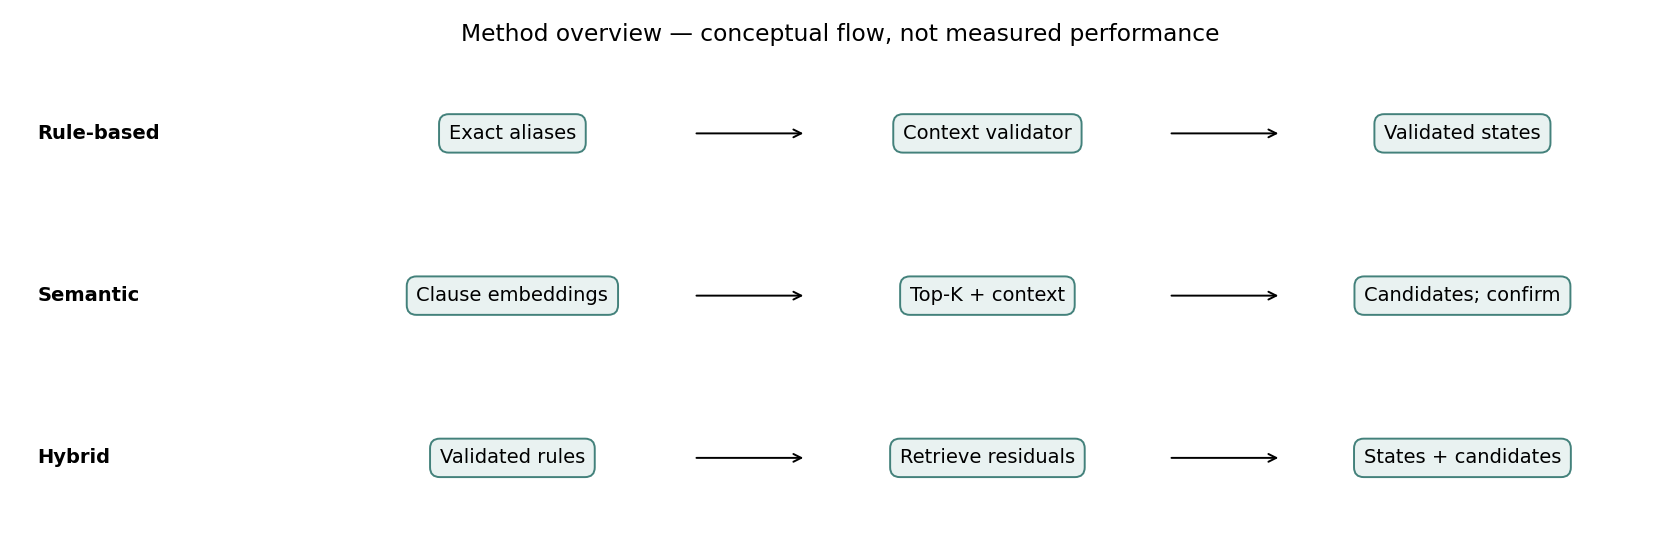

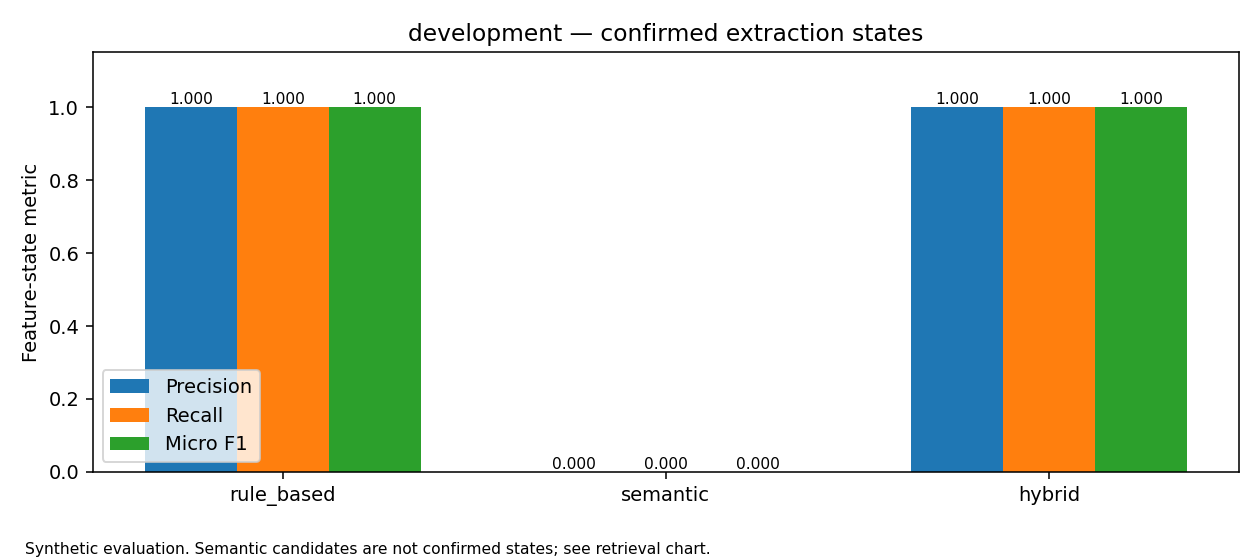

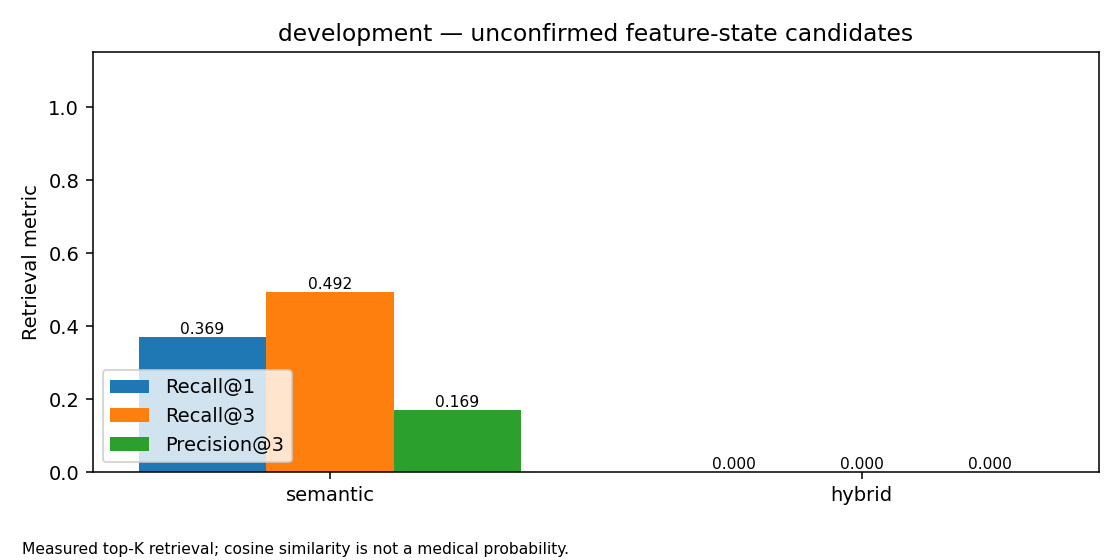

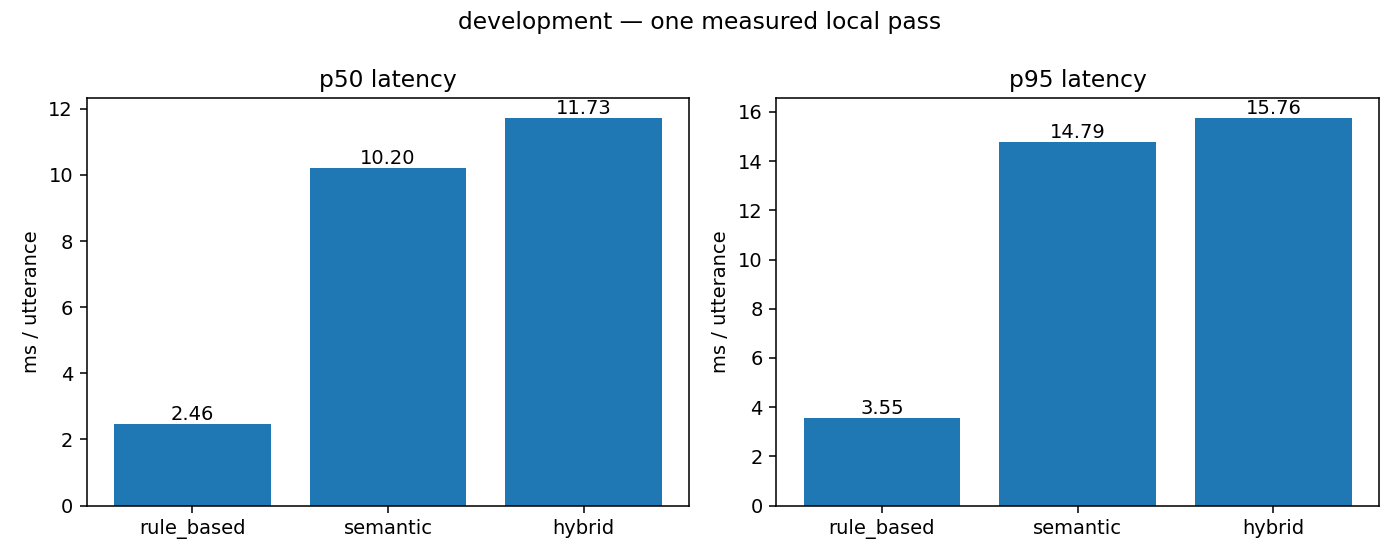

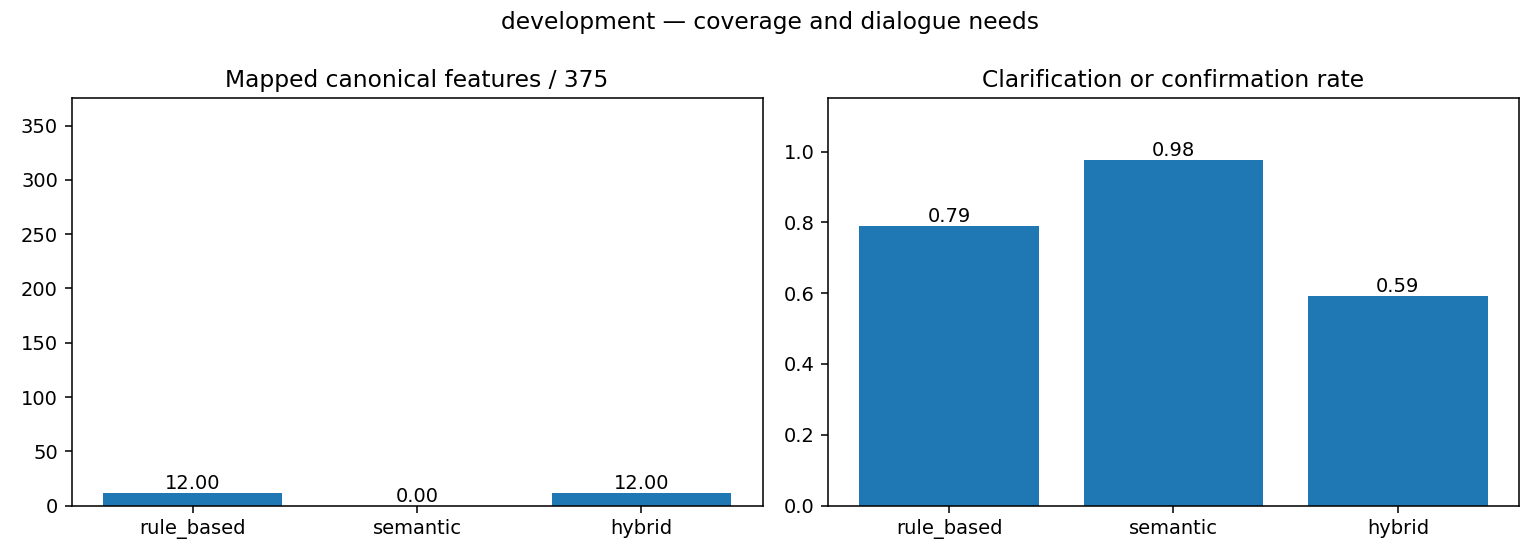

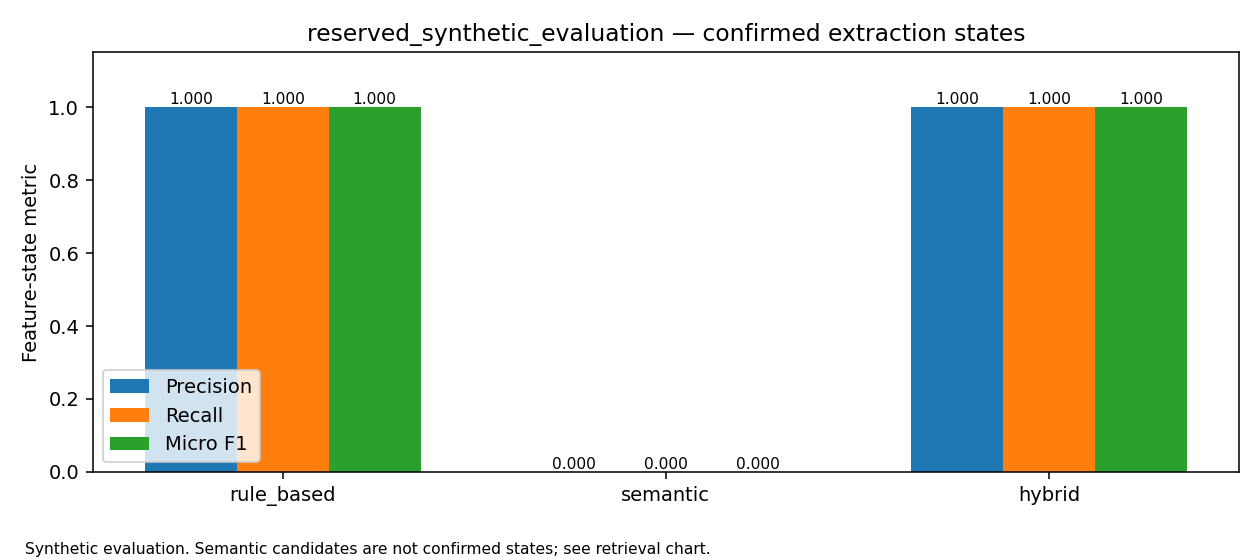

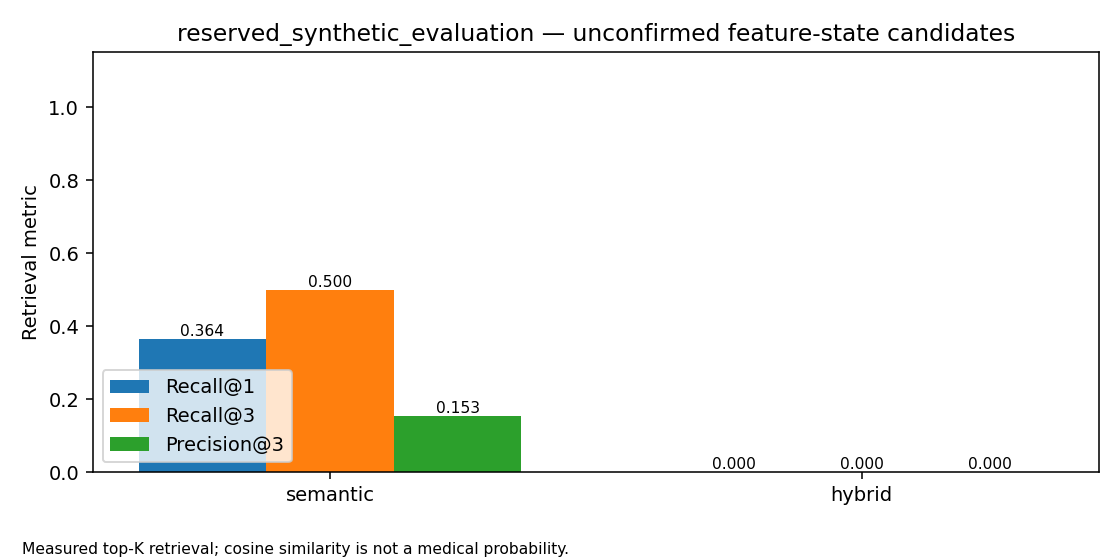

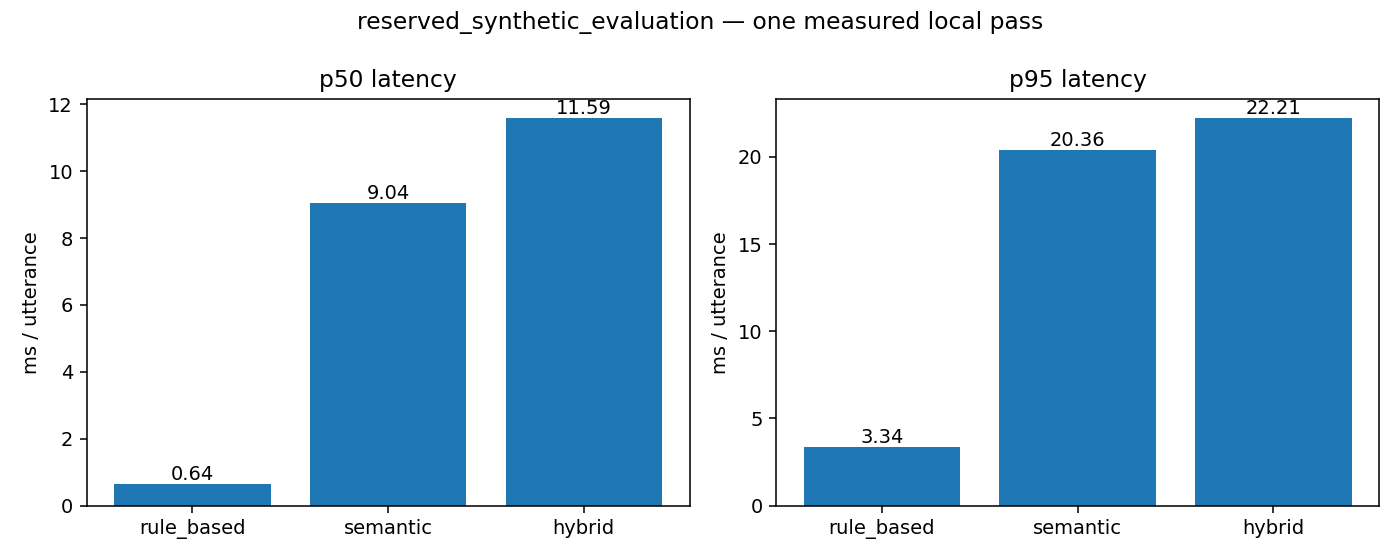

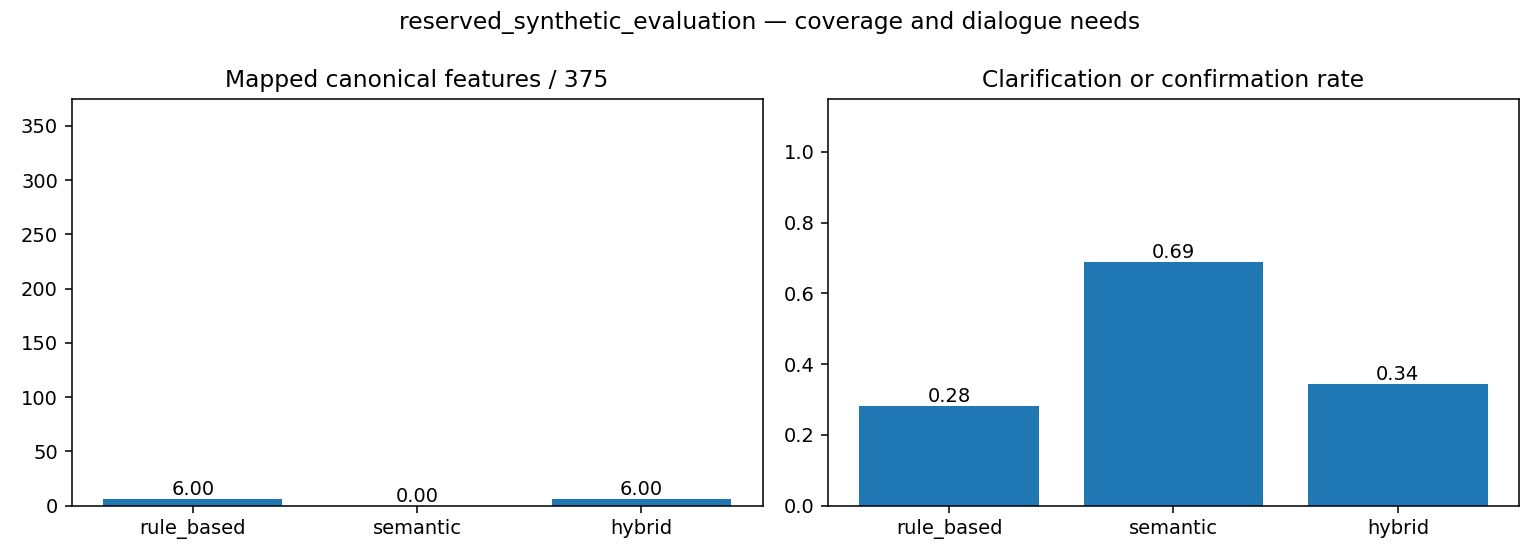

In [8]:
if RESULT_FOLDER is not None:
    manifest = json.loads((RESULT_FOLDER / 'run_figures.json').read_text(encoding='utf-8'))
    if hashlib.sha256((RESULT_FOLDER / 'benchmark.json').read_bytes()).hexdigest() != manifest['benchmark_sha256']:
        raise ValueError('Metrics/figure manifest mismatch')
    for name, expected in manifest['figures'].items():
        raw = (RESULT_FOLDER / name).read_bytes()
        if hashlib.sha256(raw).hexdigest() != expected:
            raise ValueError('Figure checksum mismatch: ' + name)
        display(Image(data=raw, format='png'))
else:
    for name in ('rule_metrics.png', 'context_errors.png', 'activation_coverage.png', 'rule_latency.png'):
        display(Image(data=snapshot_bytes(name), format='png'))


## 7.1 Lưu lại run trên Drive

Windows lưu trực tiếp trong project. Colab `/content` là tạm: cell này sao lưu nguyên thư mục run nếu Drive đã mount và canonical project có sẵn; kiểm checksum, không ghi đè thư mục cũ. Nếu chưa mount, chương trình báo rõ **chưa sao lưu**; mount bằng lệnh Colab của VS Code rồi chạy lại riêng cell này. Save notebook chỉ giữ phần hiển thị, không thay thế folder JSON/CSV/PNG.


In [9]:
PERSISTENT_REPORT = None
if RESULT_FOLDER is not None:
    if IS_COLAB and SAVE_REPORTS_TO_DRIVE:
        drive_project = Path('/content/drive/MyDrive/ML_Projects/disease-prediction-ml')
        if not drive_project.is_dir():
            print('CHƯA SAO LƯU DRIVE. Run hiện ở:', RESULT_FOLDER)
            print('Mount Drive trong VS Code, rồi chạy lại riêng cell lưu kết quả này trước khi xóa runtime.')
        else:
            save_command = [sys.executable, '-B', '-c',
                'from scripts.nlp_symptom_research import persist_report; import json,sys; print(json.dumps(persist_report(sys.argv[1],sys.argv[2])))',
                str(RESULT_FOLDER), str(drive_project)]
            saved_copy = subprocess.run(save_command, cwd=ROOT, capture_output=True, text=True)
            if saved_copy.returncode:
                print('Chưa xác nhận sao lưu Drive:', saved_copy.stderr[-800:])
            else:
                PERSISTENT_REPORT = json.loads(saved_copy.stdout)
                print('Drive:', PERSISTENT_REPORT)
    elif not IS_COLAB:
        print('Run đã lưu bền vững trên máy local:', RESULT_FOLDER)
    else:
        print('Chưa bật lưu Drive; giữ folder trước khi kết thúc runtime:', RESULT_FOLDER)


Run đã lưu bền vững trên máy local: D:\Program Files (x86)\DULIEUCODE\ML\disease-prediction-ml-git-sync\reports\nlp_research_20261111T133402584453Z


## 8. Kết luận và giới hạn

Đánh giá các phương án theo kết quả đo trong cùng run: mức cải thiện recall cần được xem cùng precision, lỗi phủ định/chủ thể, tỷ lệ cần xác nhận và độ trễ. Semantic retrieval trả về ứng viên theo độ tương đồng; Hybrid kết hợp các ứng viên này với trạng thái đã kiểm chứng từ quy tắc. Không suy chất lượng phân loại bệnh từ cosine similarity.

Baseline lưu ban đầu cho thấy lỗi hư cấu trên reserved synthetic set; guard được sửa theo câu chứa evidence và có regression riêng. Giữ kết quả lịch sử để đối chiếu phiên bản, không coi rerun trên tập đã quan sát là bằng chứng tổng quát hóa độc lập.

Giữ nguyên 135 production features cho đến khi aliases vượt context, semantic-overlap và batch release checks; inventory đầy đủ không tự cho phép activation. Các giả định của nhãn tổng hợp, collision không dấu, typo, phủ định phức tạp, đồng nghĩa và cách nói ngoài catalog vẫn cần người duyệt. 32 câu synthetic không đủ chứng minh chất lượng extraction ngoài đời.

Xem [README](../README.md), [NLP contract](../docs/phase5_llm_integration_design.md), [development log](../docs/DEVELOPMENT_LOG.md). Notebook 01–06, model LR tuned, VT318, schema375/class587 và scientific results không được sửa bởi nghiên cứu này.


In [10]:
if research is not None:
    conclusion=[]
    for split,methods in research['results'].items():
        rule=methods['rule_based']['metrics']
        sem=methods.get('semantic',{})
        hybrid=methods.get('hybrid',{})
        supplement=sum(bool(r.get('suggestions')) for r in hybrid.get('rows',[]))
        conclusion.append({'split':split,'Số câu':rule['cases'],'Câu có nhãn đầy đủ':rule['fully_annotated_cases'],
            'Rule Micro F1':rule['micro_f1'],'Semantic Recall@3':sem.get('candidate_metrics',{}).get('recall_at_3'),
            'Hybrid Micro F1 (states)':hybrid.get('metrics',{}).get('micro_f1'),
            'Câu Hybrid có ứng viên bổ sung':supplement})
    display(pd.DataFrame(conclusion))
    print('Semantic/Hybrid đã chạy nếu trạng thái run báo hoàn tất; ứng viên bổ sung chưa được tự xác nhận.')
    print('Hybrid F1 bằng Rule-based là kết quả của chế độ giữ validated states, không chứng minh hai cách matching giống nhau.')
    print('Kết quả áp dụng cho fixtures synthetic đã quan sát; không suy chất lượng ngoài đời hoặc độ chính xác chẩn đoán.')
else:
    print('Kết luận snapshot chỉ áp dụng phiên bản lịch sử đang xem.')


,split,Số câu,Câu có nhãn đầy đủ,Rule Micro F1,Semantic Recall@3,Hybrid Micro F1 (states),Câu Hybrid có ứng viên bổ sung
0,development,86,63,1.0,0.492308,1.0,51
1,reserved_synthetic_evaluation,32,32,1.0,0.500000,1.0,11


Semantic/Hybrid đã chạy nếu trạng thái run báo hoàn tất; ứng viên bổ sung chưa được tự xác nhận.
Hybrid F1 bằng Rule-based là kết quả của chế độ giữ validated states, không chứng minh hai cách matching giống nhau.
Kết quả áp dụng cho fixtures synthetic đã quan sát; không suy chất lượng ngoài đời hoặc độ chính xác chẩn đoán.


## 9. Ranh giới tái sử dụng cho website sau này

Notebook chỉ điều phối setup, benchmark và trình bày. Matching trả dữ liệu canonical (`states`, `evidence`, `schema_sha256`, `subject_id`) và danh sách candidates riêng; đọc/ghi report, download và vẽ hình nằm ngoài đường xử lý một message. Embedding/dictionary được khởi tạo một lần, không tải lại theo request. Không có module web mới hoặc thay đổi production runtime trong notebook này.

Khi chuyển sang Python phục vụ web, adapter phải đưa actual user turns/evidence qua ExtractionValidator và DecisionPolicy hiện có; không nhận confirmed states trực tiếp từ client hoặc tự biến cosine thành present. Giữ session/state theo chủ thể ở conversation layer, không dùng biến global của notebook. Input bệnh luôn375 feature theo schema; denied/uncertain/unmentioned không được tự coi là clinically absent. Chỉ tạo vector và gọi LR sau quality gate. Đây là yêu cầu giao diện cho bước tích hợp, không tuyên bố file notebook đã là một web extractor hoàn chỉnh.


## 10. Semantic có cứu được triệu chứng Rule-based bỏ sót không?

Đây là phép đo bổ sung **cùng input cho ba phương pháp**, không thay các output lịch sử ở trên. Bộ challenge synthetic có 30 câu, chia trước thành 5 nhóm × 6 câu; toàn bộ câu đều được tính, không chỉ chọn ca Semantic đúng. Nhãn do dự án viết, pending_human_review, không phải đánh giá lâm sàng hoặc tập test độc lập.

| Nhóm | Câu hỏi nghiên cứu |
|---|---|
| Alias có sẵn | Hybrid có giữ nguyên rule states, có tạo thêm câu hỏi không cần thiết không? |
| Diễn đạt mới dự kiến | Semantic có truy hồi feature bị bỏ sót không? Mức bỏ sót được đo lại theo dictionary hiện hành, không mặc định mọi câu đều mới. |
| Nhiều triệu chứng | Đã tìm thấy sốt/ho có còn truy hồi được triệu chứng thứ hai, thứ ba không? |
| Phủ định, uncertainty, chủ thể khác, hư cấu | Có đề xuất hoặc xác nhận sai triệu chứng present không? |
| Nhập nhằng | Có giữ abstain và yêu cầu làm rõ thay vì tự chốt feature không? |

**Sửa phép đo Hybrid:** chỉ che đúng evidence span đã được rules xử lý, giữ offset/context gốc, truy hồi phần còn lại; loại từng feature đã có thay vì bỏ cả Top3 khi một ứng viên trùng rule. Ví dụ “Tôi bị sốt, với lại mỗi lần vận động cứ thấy không lấy đủ hơi” phải vẫn xem xét phần sau. Hai feature gần nghĩa `shortness of breath` và `difficulty breathing` vẫn báo khác canonical key, không fuzzy-gộp để tăng điểm; annotation này có giới hạn ngữ nghĩa.

**Các tầng metric cần phân biệt:**

- Báo thêm feature-only Recall@3 để phân biệt tìm đúng feature nhưng sai assertion với thu hồi đúng. Missed Recall@1/@3 (feature + present) chỉ có mẫu số là gold **present bị Rule-based bỏ sót**; nếu mẫu số 0 báo N/A. Rule-based không có cơ chế candidate nên recall cứu bỏ sót bằng 0 khi có mẫu số.
- Candidate false-discovery fraction là số candidate present ngoài gold / candidate present đã đề xuất trên câu có nhãn đầy đủ; loại nhóm nhập nhằng khỏi mẫu số âm tính. Nhóm nhập nhằng chỉ báo câu hỏi và số lần tự gán feature; không gọi đó là FPR trên 375 âm tính. Protected false-positive rate dùng số câu phủ định/chủ thể cần bảo vệ làm mẫu số. Báo riêng exposure ở candidates và false positive ở committed states.
- Precision sau xác nhận người dùng thật hiện **NOT VERIFIED**. `oracle_precision/recall` chỉ là cận trên giả định người trả lời hoàn hảo theo annotation, không phải kết quả hội thoại thực. Không cộng oracle vào model output hoặc LR.
- Confirmation burden dùng chung một đơn vị: **một danh sách ứng viên = một câu hỏi dự kiến**; không tự xem đó là số lượt người dùng đã trả lời. Các câu hỏi quality gate của rule không cộng lẫn vào chỉ số này.
- Latency p50/p95, số câu cần query embedding và số query thực tế; load/catalog encoding và warm-up báo riêng. Không inference bệnh, không LLM API, không chọn threshold.

Cell sau dùng embedding local đã kiểm từ setup07. Khi RUN_RESEARCH/RUN_SEMANTIC bật, chạy và lưu riêng `reports/nlp_research_missed_<timestamp>/`; không ghi đè báo cáo cũ hoặc đổi extractor trên web.


### Kết quả paired challenge — đủ 5 nhóm

,group,method,cases,rule_missed_present_pairs,missed_recall_at_1,missed_recall_at_3,feature_only_missed_recall_at_3,rule_states_lost
0,all,rule_based,30,12,0.000000,0.000000,0.000000,0
1,all,semantic,30,12,0.166667,0.166667,0.416667,20
2,all,hybrid,30,12,0.083333,0.083333,0.333333,0
3,known_alias,rule_based,6,0,NaN,NaN,NaN,0
4,known_alias,semantic,6,0,NaN,NaN,NaN,8
5,known_alias,hybrid,6,0,NaN,NaN,NaN,0
6,novel_expression,rule_based,6,6,0.000000,0.000000,0.000000,0
7,novel_expression,semantic,6,6,0.166667,0.166667,0.333333,2
8,novel_expression,hybrid,6,6,0.166667,0.166667,0.333333,0
9,multiple_symptoms,rule_based,6,6,0.000000,0.000000,0.000000,0


,group,method,candidate_false_discovery_fraction,protected_candidate_exposure_rate,protected_committed_false_positive_rate,committed_precision,ambiguous_automatic_assignment_cases,oracle_precision,oracle_recall,real_user_post_confirmation_precision
0,all,rule_based,NaN,0.0,0.0,0.900,0,0.900000,0.600000,None
1,all,semantic,0.808824,0.0,0.0,NaN,0,1.000000,0.466667,None
2,all,hybrid,0.958333,0.0,0.0,0.900,0,0.904762,0.633333,None
3,known_alias,rule_based,NaN,NaN,NaN,1.000,0,1.000000,1.000000,None
4,known_alias,semantic,0.750000,NaN,NaN,NaN,0,1.000000,0.750000,None
5,known_alias,hybrid,NaN,NaN,NaN,1.000,0,1.000000,1.000000,None
6,novel_expression,rule_based,NaN,NaN,NaN,0.500,0,0.500000,0.142857,None
7,novel_expression,semantic,0.933333,NaN,NaN,NaN,0,1.000000,0.142857,None
8,novel_expression,hybrid,0.933333,NaN,NaN,0.500,0,0.666667,0.285714,None
9,multiple_symptoms,rule_based,NaN,NaN,NaN,0.875,0,0.875000,0.538462,None


,group,method,candidate_list_questions,questions_per_utterance,utterances_requiring_embedding,embedding_calls,latency_p50_ms,latency_p95_ms
0,all,rule_based,0,0.000000,0,0,0.98390,3.989125
1,all,semantic,38,1.266667,26,38,10.66170,20.868180
2,all,hybrid,23,0.766667,20,23,10.07190,18.882870
3,known_alias,rule_based,0,0.000000,0,0,3.46255,5.060500
4,known_alias,semantic,8,1.333333,6,8,11.11505,19.991100
5,known_alias,hybrid,0,0.000000,0,0,3.49390,5.104700
6,novel_expression,rule_based,0,0.000000,0,0,0.77850,1.418825
7,novel_expression,semantic,7,1.166667,6,7,9.92300,15.231100
8,novel_expression,hybrid,7,1.166667,6,7,10.26900,17.885250
9,multiple_symptoms,rule_based,0,0.000000,0,0,1.03540,1.352250


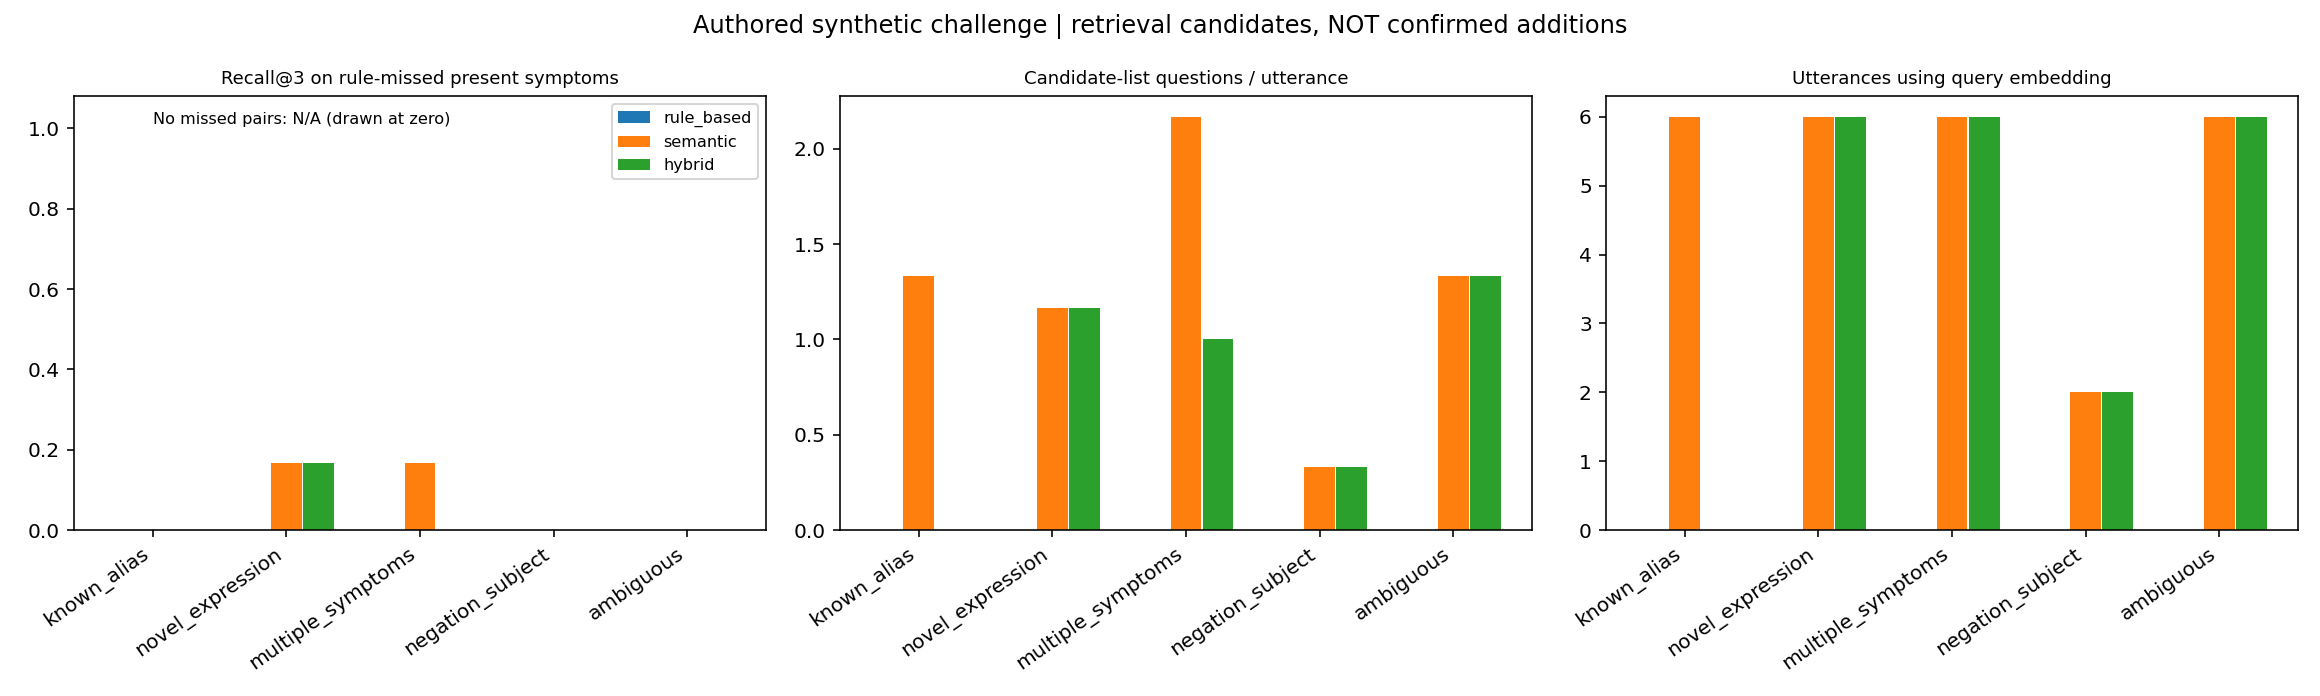

,ID,Nhóm,Input,Gold,Rule,Present bị bỏ sót,Semantic Top3,Hybrid phần còn lại
0,missed-v1-001,known_alias,Tôi bị ho.,{'cough': 'present'},{'cough': 'present'},[],"[[nausea, vomiting, feeling hot and cold]]",[]
1,missed-v1-002,known_alias,Tôi bị sốt.,{'fever': 'present'},{'fever': 'present'},[],"[[fever, flu-like syndrome, fluid retention]]",[]
2,missed-v1-003,known_alias,Tôi bị buồn nôn.,{'nausea': 'present'},{'nausea': 'present'},[],"[[vomiting, nausea, excessive appetite]]",[]
3,missed-v1-004,known_alias,Tôi bị đau đầu.,{'headache': 'present'},{'headache': 'present'},[],"[[headache, ear pain, neck pain]]",[]
4,missed-v1-005,known_alias,Tôi bị ho và tôi bị sốt.,"{'cough': 'present', 'fever': 'present'}","{'cough': 'present', 'fever': 'present'}",[],"[[nausea, vomiting, feeling hot and cold], [fever, flu-like syndrome, fluid retention]]",[]
5,missed-v1-006,known_alias,Tôi bị buồn nôn và tôi bị đau đầu.,"{'nausea': 'present', 'headache': 'present'}","{'nausea': 'present', 'headache': 'present'}",[],"[[vomiting, nausea, excessive appetite], [headache, ear pain, neck pain]]",[]
6,missed-v1-007,novel_expression,Tôi cứ có cảm giác sắp ói ra.,{'nausea': 'present'},{'vomiting': 'present'},"[[nausea, present]]","[[pelvic pressure, feeling hot and cold, throat feels tight]]","[[feeling hot and cold, pelvic pressure, throat feels tight]]"
7,missed-v1-008,novel_expression,Tôi thấy căn phòng như đang quay vòng quanh mình.,{'dizziness': 'present'},{},"[[dizziness, present]]","[[feet turned in, pelvic pressure, spots or clouds in vision]]","[[feet turned in, pelvic pressure, spots or clouds in vision]]"
8,missed-v1-009,novel_expression,Tôi rã rời hết sức dù chỉ làm việc nhẹ.,{'fatigue': 'present'},{},"[[fatigue, present]]","[[fatigue, premenstrual tension or irritability, problems with orgasm]]","[[fatigue, premenstrual tension or irritability, problems with orgasm]]"
9,missed-v1-010,novel_expression,Tôi cứ muốn uống nước mãi vì cảm giác khát.,{'thirst': 'present'},{},"[[thirst, present]]","[[thirst, frequent urination, polyuria]]","[[thirst, frequent urination, polyuria]]"


Gold present bị rule bỏ sót: 12
Semantic / Hybrid Recall@3 trên phần bỏ sót: 0.16666666666666666 / 0.08333333333333333
Hybrid làm mất rule states: 0
Load + catalog / warm-up (ms): 9316.315799951553 / 11.735499952919781
Precision sau xác nhận thật: NOT VERIFIED; oracle chỉ là cận trên synthetic. Không tự loại Semantic từ F1 committed = 0.
Report: D:\Program Files (x86)\DULIEUCODE\ML\disease-prediction-ml-git-sync\reports\nlp_research_missed_20261112T014136479026Z | SHA256: 4055f904c7f6d0ea812bdd14dba98ec64761fbe664d56d7ce645cc849436acfc


In [1]:
MISSED_FOLDER = None
if RUN_RESEARCH and RUN_SEMANTIC:
    from datetime import datetime, timezone
    MISSED_FOLDER = ROOT / 'reports' / ('nlp_research_missed_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
    snapshot = ROOT / 'artifacts/embeddings/multilingual-minilm-l12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42'
    command = [sys.executable, '-B', '-m', 'scripts.nlp_missed_symptom_analysis', '--output', str(MISSED_FOLDER), '--embedding-snapshot', str(snapshot)]
    check = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, encoding='utf-8')
    if check.returncode:
        raise RuntimeError('Phép đo triệu chứng bỏ sót chưa hoàn tất:\n' + check.stderr[-2000:])
    manifest = json.loads((MISSED_FOLDER/'manifest.json').read_text(encoding='utf-8'))
    for name, expected in manifest['files'].items():
        assert hashlib.sha256((MISSED_FOLDER/name).read_bytes()).hexdigest() == expected
    missed = json.loads((MISSED_FOLDER/'missed_analysis.json').read_text(encoding='utf-8'))
    display(Markdown('### Kết quả paired challenge — đủ 5 nhóm'))
    frame = pd.DataFrame(missed['summary'])
    display(frame[['group','method','cases','rule_missed_present_pairs','missed_recall_at_1','missed_recall_at_3','feature_only_missed_recall_at_3','rule_states_lost']])
    display(frame[['group','method','candidate_false_discovery_fraction','protected_candidate_exposure_rate','protected_committed_false_positive_rate','committed_precision','ambiguous_automatic_assignment_cases','oracle_precision','oracle_recall','real_user_post_confirmation_precision']])
    display(frame[['group','method','candidate_list_questions','questions_per_utterance','utterances_requiring_embedding','embedding_calls','latency_p50_ms','latency_p95_ms']])
    display(Image(filename=str(MISSED_FOLDER/'missed_recovery.png')))
    details=[]
    for row in missed['rows']:
        details.append({'ID':row['id'],'Nhóm':row['group'],'Input':row['text'],'Gold':row['expected_states'],
            'Rule':row['methods']['rule_based']['states'],'Present bị bỏ sót':row['missed_present'],
            'Semantic Top3':[[c['feature'] for c in p['candidates']] for p in row['methods']['semantic']['suggestions']],
            'Hybrid phần còn lại':[[c['feature'] for c in p['candidates']] for p in row['methods']['hybrid']['suggestions']]})
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', 110):
        display(pd.DataFrame(details))
    overall = frame[frame['group']=='all'].set_index('method')
    print('Gold present bị rule bỏ sót:', int(overall.loc['hybrid','rule_missed_present_pairs']))
    print('Semantic / Hybrid Recall@3 trên phần bỏ sót:', overall.loc['semantic','missed_recall_at_3'], '/', overall.loc['hybrid','missed_recall_at_3'])
    print('Hybrid làm mất rule states:', int(overall.loc['hybrid','rule_states_lost']))
    print('Load + catalog / warm-up (ms):', missed['model_load_and_catalog_ms'], '/', missed['warmup_ms'])
    print('Precision sau xác nhận thật: NOT VERIFIED; oracle chỉ là cận trên synthetic. Không tự loại Semantic từ F1 committed = 0.')
    print('Report:', MISSED_FOLDER, '| SHA256:', hashlib.sha256((MISSED_FOLDER/'missed_analysis.json').read_bytes()).hexdigest())
else:
    print('Phép đo phần bỏ sót cần RUN_RESEARCH=True và RUN_SEMANTIC=True; không suy kết quả từ snapshot cũ.')


### Kết luận theo đúng câu hỏi nghiên cứu

Các hình cũ mô tả chất lượng confirmed extraction, candidate retrieval, latency và phạm vi fixture đã quan sát. Rule Micro F1 = 1 trên các fixture đó **không chứng minh không cần Semantic**, vì gold đã được dictionary bao phủ tốt; Semantic committed F1 = 0 phản ánh chưa xác nhận candidates, không phải embedding không hoạt động. Tỷ lệ confirmation ở hình lịch sử có khác đơn vị giữa các phương pháp, không dùng nó để kết luận Hybrid hỏi ít hơn.

Đọc bảng bổ sung theo thứ tự: (1) có bao nhiêu present thực sự bị rules bỏ sót, (2) Semantic/Hybrid tìm lại được bao nhiêu trong TopK, (3) bao nhiêu candidate sai và câu hỏi thêm, (4) có giữ rule states và bảo vệ phủ định/chủ thể không, (5) chi phí embedding. Nếu có thu hồi đúng thì đó là bằng chứng Semantic hữu ích ở tầng gợi ý; nếu không thì chỉ kết luận trên challenge này. Không đổi thuật toán/threshold sau khi nhìn điểm để ép Hybrid thắng.

**Quyết định triển khai:** giữ Rule-based làm phương pháp trích xuất đặc trưng mặc định và duy nhất trên web trong phạm vi đồ án hiện tại; không tích hợp thêm Semantic hoặc Hybrid. Hai phương pháp được giữ trong notebook để trình bày và đối chiếu kết quả nghiên cứu. Quyết định này dựa trên chất lượng đầu ra cuối cùng, độ nhiễu ứng viên, số câu hỏi dự kiến và chi phí xử lý đã quan sát; không phủ nhận khả năng truy hồi bổ sung của embedding.

### Nhận định từ lần chạy thực tế ngày 12/11/2026

Run `nlp_research_missed_20261112T014136479026Z`, embedding MiniLM đã kiểm snapshot, chạy local Python 3.11.9, không gọi mạng trong benchmark:

| Kết quả trên 30 câu | Rule-based | Semantic | Hybrid phần chưa xử lý |
|---|---:|---:|---:|
| Gold present bị Rule-based bỏ sót (mẫu số chung) | 12 | 12 | 12 |
| Tìm đúng feature trong Top3, chưa xét assertion | 0/12 | 5/12 | 4/12 |
| Thu hồi đúng feature **và present** trong Top3 | 0/12 | 2/12 | 1/12 |
| Query embedding thực tế | 0 | 38 | 23 |
| Câu hỏi danh sách ứng viên dự kiến | 0 | 38 | 23 |
| p50 / p95 (ms mỗi câu, một lượt đo local) | 0,98 / 3,99 | 10,66 / 20,87 | 10,07 / 18,88 |

- **Hình missed recovery:** Semantic có tìm được feature bị rules bỏ sót; lợi ích chưa bằng số lần tìm đúng tên vì assertion còn sai. Hybrid chưa vượt Semantic trên challenge này. Trong riêng 6 câu nhiều triệu chứng, Semantic thu hồi đúng present 1/6 và Hybrid 0/6. Giữ cả những ca thất bại, không bỏ chúng để cải thiện điểm.
- **Nhóm alias có sẵn:** Hybrid giữ nguyên mọi rule state và không gọi query embedding trên cả 6 câu; không làm giảm kết quả nhóm này. Trên toàn challenge, Rule có 2 cặp state ngoài annotation; Hybrid giữ lại cả lỗi đó, nên “không mất rule state” không đồng nghĩa “mọi state đều đúng”. Precision committed của Rule và Hybrid là 0,90 trên nhãn đầy đủ.
- **Nhóm phủ định/chủ thể:** không tự xác nhận present sai trên 6 ca được thử. Nhóm nhập nhằng không tự gán feature, nhưng Semantic/Hybrid vẫn tạo 8 danh sách hỏi trên 6 câu; đây là chi phí và chưa chứng minh câu hỏi thực sự hữu ích. Gold={} của nhóm nhập nhằng không bị coi là 375 nhãn âm tính để tính precision.
- **Ứng viên có nhiễu:** trên câu có nhãn đầy đủ, 55/68 cặp candidate present của Semantic và 23/24 của Hybrid nằm ngoài gold. Top3 cố ý có lựa chọn thay thế, nên tỷ lệ này là độ nhiễu danh sách, không phải tỷ lệ chẩn đoán sai hoặc FPR trên toàn catalog.
- **Lỗi cụ thể cần nhìn thấy:** “rã rời hết sức” truy hồi được `fatigue` nhưng từ “hết” khiến heuristic assertion hiểu sai thành denied. Câu sốt + “không lấy đủ hơi” vẫn chưa thu hồi đúng present; chưa được gọi là ca đã sửa thành công. Không nới guard theo nhãn để ép điểm tăng.

**Kết luận thí nghiệm và lựa chọn phương pháp:** Semantic Matching có khả năng truy hồi một phần triệu chứng nằm ngoài phạm vi nhận diện của bộ trích xuất dựa trên luật. Trên challenge gồm 30 câu tiếng Việt tổng hợp, Semantic truy hồi đúng feature và trạng thái present ở 2/12 trường hợp Rule-based bỏ sót, trong khi Hybrid đạt 1/12. Tuy nhiên, hai phương pháp còn tạo nhiều ứng viên không phù hợp với nhãn tham chiếu, tăng số câu hỏi xác nhận dự kiến và chưa chứng minh được cải thiện trong kết quả trích xuất cuối cùng. Hybrid bảo toàn trạng thái Rule-based đã nhận diện nhưng mức thu hồi bổ sung còn hạn chế.

**Trong phạm vi thí nghiệm này, Semantic và Hybrid chưa vượt Rule-based về hiệu quả trích xuất cuối cùng và đánh đổi triển khai. Dự án giữ Rule-based làm mặc định, không bổ sung Semantic hoặc Hybrid vào chatbot/web.** Các kết quả Semantic/Hybrid vẫn được bảo toàn như đối chứng nghiên cứu, không chuyển thành chức năng runtime mới. Kết luận không đồng nghĩa Rule-based luôn tốt hơn trên mọi dữ liệu: bộ kiểm thử tổng hợp nhỏ này chưa chứng minh hiệu quả tổng quát trên dữ liệu người dùng thực tế.

Precision sau xác nhận thật vẫn **NOT VERIFIED**. Các giá trị oracle trong bảng chỉ dùng gold giả định câu trả lời hoàn hảo, không phải thí nghiệm với người dùng. Các paraphrase được tái dùng có chủ đích giữa nhóm câu đơn và nhiều triệu chứng để đối chiếu ảnh hưởng ngữ cảnh; không coi hai nhóm là dữ liệu kiểm định độc lập. Một annotation bỏ sót `vomiting=denied` trong câu “chưa ói” đã được bổ sung trước báo cáo cuối; không đổi matcher hoặc chọn lại câu theo kết quả. Hai run chẩn đoán trước được giữ nguyên.

Nguồn: `reports/nlp_research_missed_20261112T014136479026Z/missed_analysis.json`; SHA-256: `4055f904c7f6d0ea812bdd14dba98ec64761fbe664d56d7ce645cc849436acfc`. Figure và input/source hashes nằm trong manifest và packet của cùng run. Output mới được nhúng trong notebook; mọi cell cũ giữ nguyên source, output và execution_count.
